## Ćelija 1 - Provera GPU

In [ ]:
import torch
print('PyTorch:', torch.__version__)
print('CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    raise RuntimeError('Nema GPU! Idi na Runtime → Change runtime type → T4 GPU')

PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


## Ćelija 2 - Montiranje Drive-a

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Ćelija 3 - Provera da checkpoint postoji na Drive-u

In [ ]:
import os

CKPT_FILE = '/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_020.pth.tar'

if not os.path.exists(CKPT_FILE):
    # Pokusaj da pronadje bilo koji dostupan checkpoint
    import glob
    available = sorted(glob.glob('/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_*.pth.tar'))
    if not available:
        raise FileNotFoundError(
            'Nema checkpointa na Drive-u!\n'
            'Proveri putanju: MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/'
        )
    CKPT_FILE = available[-1]
    print(f'epoch_020 nije pronađen, koristim poslednji dostupni: {CKPT_FILE}')
else:
    print(f'Checkpoint pronađen: {CKPT_FILE}')

# Ispisi sve dostupne checkpointe
import glob
sve = sorted(glob.glob('/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_*.pth.tar'))
print(f'\nSvi dostupni checkpointi ({len(sve)}):')
for c in sve:
    print(f'  {os.path.basename(c)}')

Checkpoint pronađen: /content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_020.pth.tar

Svi dostupni checkpointi (2):
  epoch_010.pth.tar
  epoch_020.pth.tar


## Ćelija 4 - Odmotavanje ZIP podataka

Potrebno jer Colab briše lokalni disk pri restartu.

In [ ]:
ZIP_NAME  = 'finefs_extracted.zip'  # promeni ako treba
ZIP_PATH  = f'/content/drive/MyDrive/FigureSkating/{ZIP_NAME}'
DATA_ROOT = '/content/data/finefs'

os.makedirs(DATA_ROOT, exist_ok=True)

# Odmotaj samo ako vec nije odmotano
if not os.path.exists(os.path.join(DATA_ROOT, 'annotation')):
    print('Odmotavam zip (može potrajati par minuta)...')
    os.system(f'unzip -q "{ZIP_PATH}" -d "{DATA_ROOT}"')

    # Ako zip napravio extra subfolder, pomeri gore
    subdirs = [d for d in os.listdir(DATA_ROOT)
               if os.path.isdir(os.path.join(DATA_ROOT, d))]
    if len(subdirs) == 1 and subdirs[0] not in ['annotation','i3d','vggish','IBfeature']:
        inner = os.path.join(DATA_ROOT, subdirs[0])
        os.system(f'mv "{inner}"/* "{DATA_ROOT}/"')
        os.system(f'rmdir "{inner}"')
else:
    print('Podaci već postoje, preskačem unzip.')

print('\nStruktura:')
for d in sorted(os.listdir(DATA_ROOT)):
    print(f'  {d}/')

Odmotavam zip (može potrajati par minuta)...

Struktura:
  IBfeature/
  annotation/
  i3d/
  vggish/


## Ćelija 5 - Pravljenje val_annotation (ako ne postoji)

In [ ]:
import shutil

ANN_DIR = os.path.join(DATA_ROOT, 'annotation')
VAL_DIR = os.path.join(DATA_ROOT, 'val_annotation')
os.makedirs(VAL_DIR, exist_ok=True)

if len(os.listdir(VAL_DIR)) > 0:
    print(f'val_annotation već postoji ({len(os.listdir(VAL_DIR))} fajlova), preskačem.')
else:
    all_jsons = sorted(glob.glob(f'{ANN_DIR}/*.json'))
    val_jsons = all_jsons[int(len(all_jsons) * 0.8):]
    for f in val_jsons:
        shutil.copy(f, VAL_DIR)
    print(f'Trening : {len(all_jsons)} fajlova')
    print(f'Val     : {len(val_jsons)} fajlova')

Trening : 933 fajlova
Val     : 187 fajlova


## Ćelija 6 - Kloniranje koda

In [ ]:
REPO_DIR = '/content/repo'

if not os.path.exists(f'{REPO_DIR}/train.py'):
    os.system(f'git clone https://github.com/ycwfs/Figure-Skating-Action-Quality-Assessment.git "{REPO_DIR}"')
    print('Repo kloniran.')
else:
    print('Repo već postoji.')

os.chdir(REPO_DIR)
print('Radni dir:', os.getcwd())

Repo kloniran.
Radni dir: /content/repo


## Ćelija 7 - Instalacija paketa

In [ ]:
os.chdir(REPO_DIR)
!pip install -q ninja tensorboard pandas h5py joblib PyYAML scipy
!pip install -q "numpy>=1.21,<=1.23"
print('Paketi instalirani.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 7.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 97.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
Paketi instalirani.




## Ćelija 8 - Instalacija causal-conv1d

In [ ]:
os.chdir(f'{REPO_DIR}/causal-conv1d')
!pip install . --no-build-isolation -q
os.chdir(REPO_DIR)
print('causal-conv1d instaliran.')

  Preparing metadata (setup.py) ... done
causal-conv1d instaliran.


## Ćelija 9 - Instalacija Mamba SSM

In [ ]:
os.chdir(f'{REPO_DIR}/mamba')
!pip install . --no-build-isolation -q
os.chdir(REPO_DIR)
print('Mamba instaliran.')

  Preparing metadata (setup.py) ... done
Mamba instaliran.


## Ćelija 10 - Kompajliranje NMS

In [ ]:
os.chdir(f'{REPO_DIR}/libs/utils')
!python setup.py install --user -q
os.chdir(REPO_DIR)
print('NMS kompajliran.')

running install
/usr/local/lib/python3.12/dist-packages/setuptools/_distutils/cmd.py:66: SetuptoolsDeprecationWarning: setup.py install is deprecated.
!!

        ********************************************************************************
        Please avoid running ``setup.py`` directly.
        Instead, use pypa/build, pypa/installer or other
        standards-based tools.

        See https://blog.ganssle.io/articles/2021/10/setup-py-deprecated.html for details.
        ********************************************************************************

!!
  self.initialize_options()
/usr/local/lib/python3.12/dist-packages/setuptools/_distutils/cmd.py:66: EasyInstallDeprecationWarning: easy_install command is deprecated.
!!

        ********************************************************************************
        Please avoid running ``setup.py`` and ``easy_install``.
        Instead, use pypa/build, pypa/installer or other
        standards-based tools.

        See https

## Ćelija 11 - Provjera instalacija

In [ ]:
checks = [
    ('torch',         'import torch'),
    ('mamba_ssm',     'from mamba_ssm import Mamba'),
    ('causal_conv1d', 'import causal_conv1d'),
    ('numpy',         'import numpy as np'),
]
all_ok = True
for name, stmt in checks:
    try:
        exec(stmt)
        print(f'OK   {name}')
    except Exception as e:
        print(f'FAIL {name} — {e}')
        all_ok = False
print('\nSve OK! Nastavi dalje.' if all_ok else '\nNešto fali, ne nastavljaj.')

OK   torch
FAIL mamba_ssm — cannot import name 'GreedySearchDecoderOnlyOutput' from 'transformers.generation' (/usr/local/lib/python3.12/dist-packages/transformers/generation/__init__.py)
OK   causal_conv1d
OK   numpy

Nešto fali, ne nastavljaj.


In [ ]:
pip install transformers==4.37.2 -q

DEPRECATION: Loading egg at /root/.local/lib/python3.12/site-packages/nms_1d_cpu-0.0.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 86.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.37.2 which is incompatible.


In [ ]:
import subprocess
result = subprocess.run(
    ['grep', '-r', 'GreedySearchDecoderOnlyOutput', '/usr/local/lib/python3.12/dist-packages/mamba_ssm/'],
    capture_output=True, text=True
)
print(result.stdout)

/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py:from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput
/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py:    Returns: GreedySearchDecoderOnlyOutput or SampleDecoderOnlyOutput, with the following fields:
/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py:    output_cls = GreedySearchDecoderOnlyOutput if top_k == 1 else SampleDecoderOnlyOutput



In [ ]:
# Zakrpa direktno u fajlu
patch = """
try:
    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput
except ImportError:
    from transformers.generation import GenerateDecoderOnlyOutput
    GreedySearchDecoderOnlyOutput = GenerateDecoderOnlyOutput
    SampleDecoderOnlyOutput = GenerateDecoderOnlyOutput
"""

filepath = '/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py'

with open(filepath, 'r') as f:
    content = f.read()

# Zameni problematičnu liniju
old = 'from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput'
new = patch.strip()

if old in content:
    content = content.replace(old, new)
    with open(filepath, 'w') as f:
        f.write(content)
    print('Zakrpa uspešno primenjena.')
else:
    print('Linija već zamenjena ili nije pronađena.')

# Provjera
from mamba_ssm import Mamba
print('mamba_ssm OK!')

Zakrpa uspešno primenjena.


ImportError: cannot import name 'is_tf_available' from 'transformers.utils' (/usr/local/lib/python3.12/dist-packages/transformers/utils/__init__.py)

In [ ]:
# Korak 1 - potpuno ukloni i reinstaliraj transformers
!pip uninstall transformers -y -q
!pip install transformers==4.38.2 -q --no-deps
!pip install tokenizers accelerate -q

# Korak 2 - direktna zakrpa fajla (bez importa transformers)
filepath = '/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py'

with open(filepath, 'r') as f:
    content = f.read()

old = 'from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput'
new = '''try:
    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput
except ImportError:
    from dataclasses import dataclass
    import torch
    @dataclass
    class GreedySearchDecoderOnlyOutput:
        sequences: torch.LongTensor = None
        scores: tuple = None
    SampleDecoderOnlyOutput = GreedySearchDecoderOnlyOutput'''

if old in content:
    content = content.replace(old, new)
    with open(filepath, 'w') as f:
        f.write(content)
    print('Zakrpa primenjena.')
else:
    print('Već zakrpljeno.')

# Korak 3 — restart kernela i provjera
import importlib, sys
for mod in list(sys.modules.keys()):
    if 'mamba' in mod or 'transformers' in mod:
        del sys.modules[mod]

from mamba_ssm import Mamba
print('mamba_ssm OK!')

DEPRECATION: Loading egg at /root/.local/lib/python3.12/site-packages/nms_1d_cpu-0.0.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
DEPRECATION: Loading egg at /root/.local/lib/python3.12/site-packages/nms_1d_cpu-0.0.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 97.5 MB/s eta 0:00:00
DEPRECATION: Loading egg at /root/.local/lib/python3.12/site-packages/nms_1d_cpu-0.0.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Disc

IndentationError: expected an indented block after 'try' statement on line 15 (generation.py, line 16)

In [ ]:
filepath = '/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py'

with open(filepath, 'r') as f:
    content = f.read()

# Ukloni pokvarenu zakrpu i stavi ispravnu
old = '''try:
    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput
except ImportError:
    from dataclasses import dataclass
    import torch
    @dataclass
    class GreedySearchDecoderOnlyOutput:
        sequences: torch.LongTensor = None
        scores: tuple = None
    SampleDecoderOnlyOutput = GreedySearchDecoderOnlyOutput'''

new = '''try:
    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput
except ImportError:
    from dataclasses import dataclass
    import torch
    @dataclass
    class GreedySearchDecoderOnlyOutput:
        sequences: torch.LongTensor = None
        scores: tuple = None
    SampleDecoderOnlyOutput = GreedySearchDecoderOnlyOutput
'''

if old in content:
    content = content.replace(old, new)
    with open(filepath, 'w') as f:
        f.write(content)
    print('Zakrpa ispravljena.')
else:
    # Rucno pregledaj sta je u fajlu oko linije 14-16
    lines = content.split('\n')
    for i, line in enumerate(lines[12:20], start=13):
        print(f'{i}: {repr(line)}')

# Reset modula
import sys
for mod in list(sys.modules.keys()):
    if 'mamba' in mod:
        del sys.modules[mod]

from mamba_ssm import Mamba
print('mamba_ssm OK!')

Zakrpa ispravljena.


IndentationError: expected an indented block after 'try' statement on line 15 (generation.py, line 16)

In [ ]:
filepath = '/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py'

with open(filepath, 'r') as f:
    lines = f.readlines()

# Ispisi linije 12-20 da vidimo sta je trenutno tu
print('Trenutno stanje fajla (linije 12-20):')
for i, line in enumerate(lines[11:20], start=12):
    print(f'{i}: {repr(line)}')

Trenutno stanje fajla (linije 12-20):
12: 'from torch import Tensor\n'
13: 'from torch.profiler import ProfilerActivity, profile, record_function\n'
14: 'try:\n'
15: '    try:\n'
16: '    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput\n'
17: 'except ImportError:\n'
18: '    from dataclasses import dataclass\n'
19: '    import torch\n'
20: '    @dataclass\n'


In [ ]:
filepath = '/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py'

with open(filepath, 'r') as f:
    lines = f.readlines()

# Nadji dokle ide pokvareni blok
print(f'Ukupno linija: {len(lines)}')
for i, line in enumerate(lines[11:30], start=12):
    print(f'{i}: {repr(line)}')

Ukupno linija: 393
12: 'from torch import Tensor\n'
13: 'from torch.profiler import ProfilerActivity, profile, record_function\n'
14: 'try:\n'
15: '    try:\n'
16: '    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput\n'
17: 'except ImportError:\n'
18: '    from dataclasses import dataclass\n'
19: '    import torch\n'
20: '    @dataclass\n'
21: '    class GreedySearchDecoderOnlyOutput:\n'
22: '        sequences: torch.LongTensor = None\n'
23: '        scores: tuple = None\n'
24: '    SampleDecoderOnlyOutput = GreedySearchDecoderOnlyOutput\n'
25: '\n'
26: '\n'
27: 'except ImportError:\n'
28: '    from transformers.generation import GenerateDecoderOnlyOutput\n'
29: '    GreedySearchDecoderOnlyOutput = GenerateDecoderOnlyOutput\n'
30: '    SampleDecoderOnlyOutput = GenerateDecoderOnlyOutput\n'


In [ ]:
filepath = '/usr/local/lib/python3.12/dist-packages/mamba_ssm/utils/generation.py'

with open(filepath, 'r') as f:
    lines = f.readlines()

# Uzmi linije 1-13 (pre pokvarenog bloka) i od linije 31 nadalje
before = lines[:13]   # linije 1-13
after  = lines[30:]   # od linije 31 nadalje

# Ispravna zakrpa
new_lines = [
    'try:\n',
    '    from transformers.generation import GreedySearchDecoderOnlyOutput, SampleDecoderOnlyOutput\n',
    'except ImportError:\n',
    '    from dataclasses import dataclass\n',
    '    import torch\n',
    '    @dataclass\n',
    '    class GreedySearchDecoderOnlyOutput:\n',
    '        sequences: torch.LongTensor = None\n',
    '        scores: tuple = None\n',
    '    SampleDecoderOnlyOutput = GreedySearchDecoderOnlyOutput\n',
    '\n',
]

final = before + new_lines + after

with open(filepath, 'w') as f:
    f.writelines(final)

print('Fajl očišćen i prepisan.')

# Provjera
import sys
for mod in list(sys.modules.keys()):
    if 'mamba' in mod:
        del sys.modules[mod]

from mamba_ssm import Mamba
print('mamba_ssm OK!')

Fajl očišćen i prepisan.
mamba_ssm OK!




## Ćelija 12 - Kreiranje konfiguracije

In [ ]:
import yaml

REPO_DIR  = '/content/repo'
DATA_ROOT = '/content/data/finefs'
CKPT_DIR  = '/content/drive/MyDrive/FigureSkating/ckpt'

CONFIG_SRC = f'{REPO_DIR}/configs/finefs.yaml'
CONFIG_OUT = f'{REPO_DIR}/configs/finefs_colab.yaml'

with open(CONFIG_SRC, 'r') as f:
    cfg = yaml.safe_load(f)

cfg['dataset']['annotation_folder'] = DATA_ROOT
cfg['dataset']['vid_feat_folder']   = os.path.join(DATA_ROOT, 'i3d')
cfg['dataset']['aud_feat_folder']   = os.path.join(DATA_ROOT, 'vggish')
cfg['dataset']['class_path']        = os.path.join(REPO_DIR, '24_class.json')
cfg['output_folder']                = CKPT_DIR
cfg['devices']                      = ['cuda:0']

with open(CONFIG_OUT, 'w') as f:
    yaml.dump(cfg, f, default_flow_style=False)

print('Config kreiran.')
print(f'  annotation : {cfg["dataset"]["annotation_folder"]}')
print(f'  i3d        : {cfg["dataset"]["vid_feat_folder"]}')
print(f'  vggish     : {cfg["dataset"]["aud_feat_folder"]}')

Config kreiran.
  annotation : /content/data/finefs
  i3d        : /content/data/finefs/i3d
  vggish     : /content/data/finefs/vggish


## Ćelija 13 - EVALUACIJA

Koristi epoch_020.pth.tar (ili poslednji dostupni ako ga nema).

In [ ]:
os.chdir(REPO_DIR)

CKPT_FILE = '/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_020.pth.tar'

# Ako epoch_020 ne postoji, uzmi poslednji dostupni
if not os.path.exists(CKPT_FILE):
    available = sorted(glob.glob('/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_*.pth.tar'))
    CKPT_FILE = available[-1]
    print(f'Koristim: {CKPT_FILE}')

print(f'Pokrećem evaluaciju sa: {os.path.basename(CKPT_FILE)}\n')
!python eval.py "{CONFIG_OUT}" "{CKPT_FILE}"

Pokrećem evaluaciju sa: epoch_020.pth.tar

usage: eval.py [-h] [-config DIR] [-ckpt DIR] [-epoch EPOCH] [-t TOPK]
               [--saveonly] [-p PRINT_FREQ]
eval.py: error: unrecognized arguments: /content/repo/configs/finefs_colab.yaml /content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_020.pth.tar


In [ ]:
os.chdir(REPO_DIR)

CKPT_FILE = '/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_020.pth.tar'

if not os.path.exists(CKPT_FILE):
    import glob
    available = sorted(glob.glob('/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce/epoch_*.pth.tar'))
    CKPT_FILE = available[-1]

# Izvuci folder i broj epohe iz putanje
ckpt_dir   = os.path.dirname(CKPT_FILE)
epoch_num  = os.path.basename(CKPT_FILE).replace('epoch_','').replace('.pth.tar','')

print(f'Checkpoint folder : {ckpt_dir}')
print(f'Epoha             : {epoch_num}')

!python eval.py -config "{CONFIG_OUT}" -ckpt "{ckpt_dir}" -epoch "{epoch_num}"

Checkpoint folder : /content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce
Epoha             : 020
{'None': 0, 'StepSequence': 1, 'ChComboSpin': 2, 'Axel': 3, 'CamelSpin': 4, 'Loop': 5, 'Flip': 6, 'Lutz': 7, 'TripleJointJump': 8, 'Lutz_Toeloop': 9, 'Salchow': 10, 'LaybackSpin': 11, 'Toeloop': 12, 'SitSpin': 13, 'ChSitSpin': 14, 'Axel_Toeloop': 15, 'Flip_Toeloop': 16, 'Toeloop_Toeloop': 17, 'ChCamelSpin': 18, 'Salchow_Toeloop': 19, 'Lutz_Loop': 20, 'Loop_Toeloop': 21, 'ComboJump': 22, 'UpSpin': 23}
element numbers:12
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rat

## Ćelija 14 - Analiza rezultata i failure cases

In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

CKPT_FOLDER = '/content/drive/MyDrive/FigureSkating/ckpt/finefs_colab_reproduce'
pkl_files   = sorted(glob.glob(f'{CKPT_FOLDER}/finefs_eval_results_*.pkl'))

if not pkl_files:
    raise FileNotFoundError('Nema .pkl fajla. Pokreni ćeliju 13 pre ove.')

with open(pkl_files[-1], 'rb') as f:
    results = pickle.load(f)

print(f'Evaluiranih videa: {len(results)}')

rows = []
for vid_id, res in results.items():
    true_tes = sum(res.get('score_labels', [0]))
    pred_tes = sum(res.get('pred_score',   [0]))
    true_pcs = res.get('pcs_label', 0)
    pred_pcs = res.get('pred_pcs',  0)
    rows.append({
        'video_id': vid_id,
        'true_tes': round(true_tes, 2),
        'pred_tes': round(pred_tes, 2),
        'tes_err' : round(abs(pred_tes - true_tes), 2),
        'true_pcs': round(true_pcs, 2),
        'pred_pcs': round(pred_pcs, 2),
        'pcs_err' : round(abs(pred_pcs - true_pcs), 2),
        'n_el'    : len(res.get('score_labels', [])),
    })

df = pd.DataFrame(rows).sort_values('tes_err', ascending=False)

print('\n=== Statistika greške ===')
print(df[['tes_err','pcs_err']].describe().round(3))
print('\n=== Top 10 videa sa najvećom TES greškom ===')
print(df.head(10).to_string(index=False))

Evaluiranih videa: 187

=== Statistika greške ===
       tes_err  pcs_err
count  187.000  187.000
mean    10.640    0.038
std      9.303    0.029
min      0.070    0.000
25%      3.970    0.010
50%      7.790    0.030
75%     14.515    0.060
max     42.220    0.150

=== Top 10 videa sa najvećom TES greškom ===
video_id  true_tes  pred_tes  tes_err  true_pcs  pred_pcs  pcs_err  n_el
     817    100.10     57.88    42.22      0.67      0.67     0.00    12
     968     89.54     51.25    38.29      0.71      0.64     0.07    12
     887     95.70     57.82    37.88      0.67      0.65     0.02    12
     920     97.02     59.41    37.61      0.66      0.64     0.02    12
     991     97.24     61.90    35.34      0.91      0.80     0.11    12
     922     89.32     53.98    35.34      0.73      0.67     0.06    12
     916    100.32     65.48    34.84      0.94      0.79     0.15    12
     839     88.44     54.48    33.96      0.71      0.68     0.03    12
     829    102.30     68.88   

## Ćelija 15 - Grafikoni grešaka

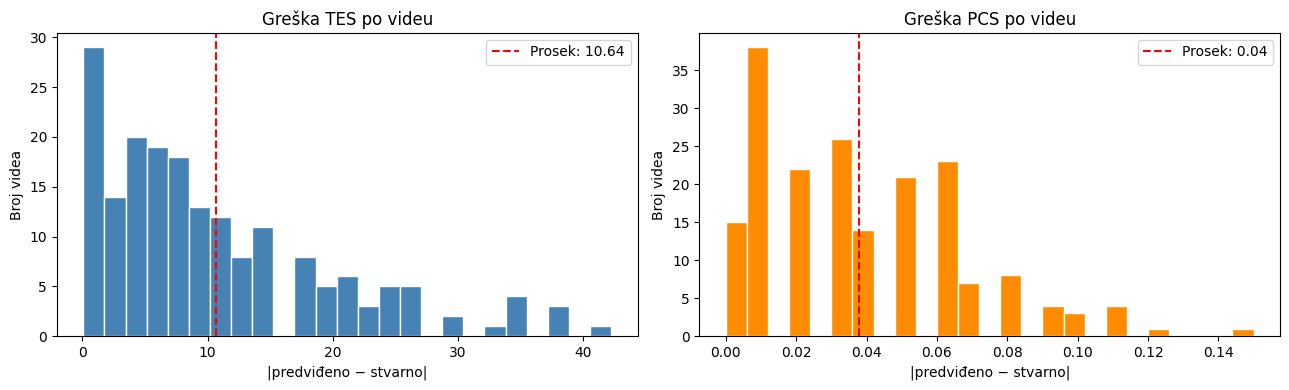

Sačuvano na Drive.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df['tes_err'], bins=25, color='steelblue', edgecolor='white')
axes[0].axvline(df['tes_err'].mean(), color='red', linestyle='--',
                label=f'Prosek: {df["tes_err"].mean():.2f}')
axes[0].set_title('Greška TES po videu')
axes[0].set_xlabel('|predviđeno − stvarno|')
axes[0].set_ylabel('Broj videa')
axes[0].legend()

axes[1].hist(df['pcs_err'], bins=25, color='darkorange', edgecolor='white')
axes[1].axvline(df['pcs_err'].mean(), color='red', linestyle='--',
                label=f'Prosek: {df["pcs_err"].mean():.2f}')
axes[1].set_title('Greška PCS po videu')
axes[1].set_xlabel('|predviđeno − stvarno|')
axes[1].set_ylabel('Broj videa')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FigureSkating/error_distribution.png', dpi=150)
plt.show()
print('Sačuvano na Drive.')

## Ćelija 16 - Detaljna analiza 5 najgorih videa

In [ ]:
ANN_ALL = os.path.join(DATA_ROOT, 'annotation')

print('=== Detaljna analiza 5 najgorih videa ===\n')

for vid_id in df.head(5)['video_id'].tolist():
    res = results[vid_id]
    row = df[df['video_id'] == vid_id].iloc[0]

    print(f'─── Video {vid_id} ───')
    print(f'  TES  stvarno={row.true_tes}  predviđeno={row.pred_tes}  greška={row.tes_err}')
    print(f'  PCS  stvarno={row.true_pcs}  predviđeno={row.pred_pcs}  greška={row.pcs_err}')

    ann_path = os.path.join(ANN_ALL, f'{vid_id}.json')
    if os.path.exists(ann_path):
        with open(ann_path) as f:
            ann = json.load(f)
        for el_key, el in ann.get('executed_element', {}).items():
            scores = el.get('judge_score', [])
            info   = el.get('info', [])
            var    = round(float(np.var(scores)), 2) if scores else 0
            flags  = []
            if '*' in str(info):       flags.append('NEVALIDAN (*)')
            if var > 3.0:              flags.append(f'VISOKA VARIJANSA (σ²={var})')
            if el.get('bv', 99) == 0:  flags.append('BV=0')
            if flags:
                print(f'  ⚠️  {el["element"]:12s} → {" | ".join(flags)}')

    gt   = res.get('score_labels', [])
    pred = res.get('pred_score',   [])
    errs = [(i, abs(p-t)) for i,(p,t) in enumerate(zip(pred, gt))]
    if errs:
        wi, we = max(errs, key=lambda x: x[1])
        print(f'  Najgori element: idx={wi}, '
              f'stvarno={gt[wi]:.2f}, pred={pred[wi]:.2f}, greška={we:.2f}')
    print()

=== Detaljna analiza 5 najgorih videa ===

─── Video 817 ───
  TES  stvarno=100.1  predviđeno=57.88  greška=42.22
  PCS  stvarno=0.67  predviđeno=0.67  greška=0.0
  Najgori element: idx=2, stvarno=16.72, pred=3.45, greška=13.27

─── Video 968 ───
  TES  stvarno=89.54  predviđeno=51.25  greška=38.29
  PCS  stvarno=0.71  predviđeno=0.64  greška=0.07
  Najgori element: idx=0, stvarno=19.36, pred=3.30, greška=16.06

─── Video 887 ───
  TES  stvarno=95.7  predviđeno=57.82  greška=37.88
  PCS  stvarno=0.67  predviđeno=0.65  greška=0.02
  Najgori element: idx=6, stvarno=18.26, pred=3.91, greška=14.35

─── Video 920 ───
  TES  stvarno=97.02  predviđeno=59.41  greška=37.61
  PCS  stvarno=0.66  predviđeno=0.64  greška=0.02
  Najgori element: idx=2, stvarno=15.18, pred=3.42, greška=11.76

─── Video 991 ───
  TES  stvarno=97.24  predviđeno=61.9  greška=35.34
  PCS  stvarno=0.91  predviđeno=0.8  greška=0.11
  Najgori element: idx=1, stvarno=13.64, pred=3.00, greška=10.64





## Ćelija 17 - Grafikon score-ova za 3 najgora primera

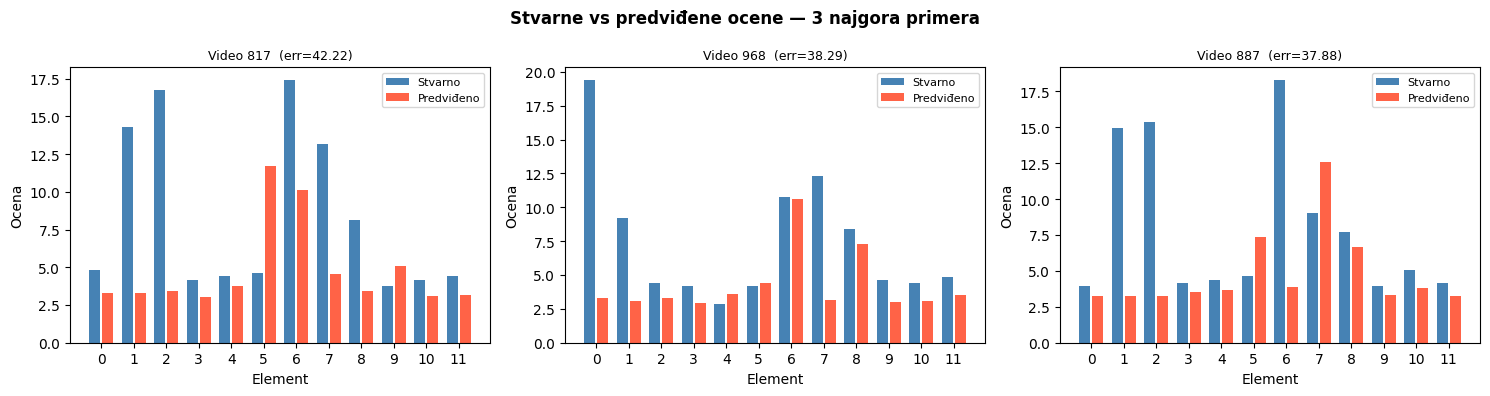

Sačuvano na Drive.


In [ ]:
worst_ids = df.head(3)['video_id'].tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, vid_id in zip(axes, worst_ids):
    res  = results[vid_id]
    gt   = res.get('score_labels', [])
    pred = res.get('pred_score',   [])
    n    = min(len(gt), len(pred))
    x    = list(range(n))

    ax.bar([i-0.2 for i in x], gt[:n],   0.35, label='Stvarno',    color='steelblue')
    ax.bar([i+0.2 for i in x], pred[:n], 0.35, label='Predviđeno', color='tomato')
    err = df[df.video_id==vid_id].tes_err.values[0]
    ax.set_title(f'Video {vid_id}  (err={err:.2f})', fontsize=9)
    ax.set_xlabel('Element')
    ax.set_ylabel('Ocena')
    ax.legend(fontsize=8)
    ax.set_xticks(x)

plt.suptitle('Stvarne vs predviđene ocene — 3 najgora primera', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/FigureSkating/worst_cases.png', dpi=150)
plt.show()
print('Sačuvano na Drive.')

## Ćelija 18 - Finalni sažetak

In [ ]:
print('=' * 50)
print('REZULTATI EVALUACIJE')
print('=' * 50)
print(f'Checkpoint      : {os.path.basename(CKPT_FILE)}')
print(f'Evaluiranih vid.: {len(results)}')
print(f'MAE TES         : {df.tes_err.mean():.3f}')
print(f'MAE PCS         : {df.pcs_err.mean():.3f}')
print()
print('TOP 5 FAILURE CASES:')
for _, r in df.head(5).iterrows():
    print(f'  Video {r.video_id:>6}: TES_err={r.tes_err:.2f}  PCS_err={r.pcs_err:.2f}')
print('=' * 50)

REZULTATI EVALUACIJE
Checkpoint      : epoch_020.pth.tar
Evaluiranih vid.: 187
MAE TES         : 10.640
MAE PCS         : 0.038

TOP 5 FAILURE CASES:
  Video    817: TES_err=42.22  PCS_err=0.00
  Video    968: TES_err=38.29  PCS_err=0.07
  Video    887: TES_err=37.88  PCS_err=0.02
  Video    920: TES_err=37.61  PCS_err=0.02
  Video    991: TES_err=35.34  PCS_err=0.11
